# 🔭 **Explore the collection**

What is in this collection, when it was collected and what it looks like.

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src import eda
from src.collection import Collection

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

&nbsp;

### 📂 **Open collection**

In [3]:
collection = Collection()

Open Collection: E:\Resources\Eyeris\Test


&nbsp;

### 🖼️ **Load all images**

`add_features` adds the extended properties: color group, lightness, local time, megapixels, aspect, folder, ...

In [4]:
images = eda.add_features(collection.images_df())
images[eda.EXTENDED].head(5)

,fullname,color_group,bucket,hour,weekday,megapixels,tier,aspect,folder
0,012.webp,lime,mid,12,Monday,8.2944,4K+,16:9,Dataset
1,voxel-houses-monochrome.webp,gray,mid,12,Monday,8.2944,4K+,16:9,Dataset
2,house_garden.webp,yellow,light,12,Monday,8.2944,4K+,16:9,Dataset
3,macos-sonoma-wallpapers-5120x2160-v0-q59obfq8h...,gray,mid,12,Monday,11.0592,4K+,21:9,Dataset
4,dream-river-4k.webp,purple,mid,12,Monday,8.2944,4K+,16:9,Dataset


&nbsp;

### 🩺 **Data audit**

#### 🚫 Null rate and value range of every column

In [4]:
eda.audit(images)

,null_%,min,max
id,0.00,NaN,NaN
origin,0.00,NaN,NaN
fullname,0.00,NaN,NaN
name,0.00,NaN,NaN
format,0.00,NaN,NaN
size,0.00,6.155500e+04,2.413662e+07
width,0.00,1.024000e+03,7.680000e+03
height,0.00,7.960000e+02,6.144000e+03
created,0.00,1.788405e+12,1.794204e+12
modified,0.00,1.752668e+12,1.792316e+12


#### ⭐ Rated and 🏷️ tagged

In [5]:
print(f"Rated:  {images['rated'].mean():.0%}")  # 0 = unrated
print(f"Tagged: {(images['n_tags'] > 0).mean():.0%}")

Rated:  53%
Tagged: 74%


#### 🕑 Suspicious timestamps

Many files in 1 minute = bulk copy or fallback time

In [8]:
print("Created range:", images["created_dt"].min(), "->", images["created_dt"].max())
images["created_dt"].dt.floor("min").value_counts().head(3)

Created range: 2026-09-03 10:08:25.250000+07:00 -> 2026-11-09 12:59:51.680000+07:00


created_dt
2026-11-09 12:59:00+07:00    89
2026-09-03 10:08:00+07:00     3
2026-09-03 14:42:00+07:00     1
Name: count, dtype: int64

&nbsp;

### 🧬 **Extended properties**

#### 📂 Top source folders

<Axes: ylabel='folder'>

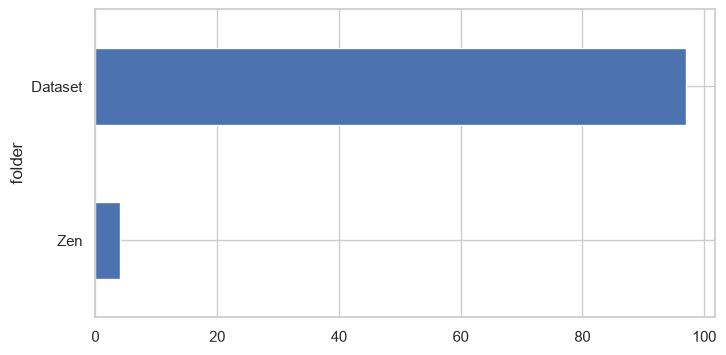

In [9]:
images["folder"].value_counts().head(10)[::-1].plot.barh()

&nbsp;

### 📊 **Basic**

#### 📄 Formats: most common

<Axes: xlabel='count', ylabel='format'>

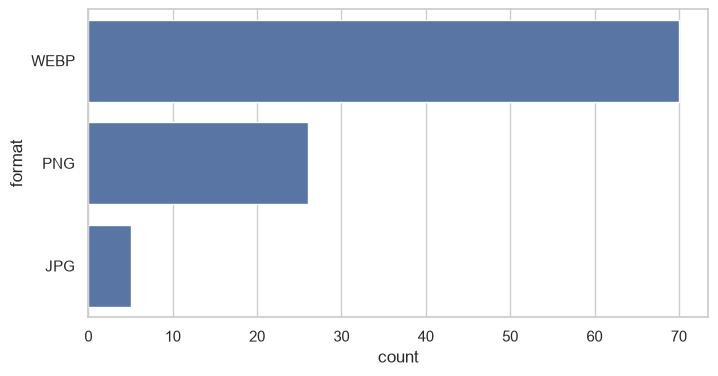

In [10]:
sns.countplot(images, y="format", order=images["format"].value_counts().index)

#### 📄 Formats: share of files vs share of disk

Text(0, 0.5, '%')

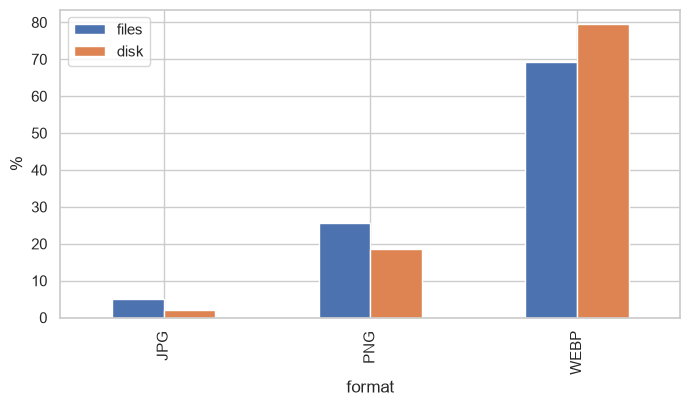

In [11]:
eda.share_files_vs_disk(images, "format").plot.bar()
plt.ylabel("%")

#### 📄 Formats: bytes per pixel

<Axes: xlabel='format', ylabel='bpp'>

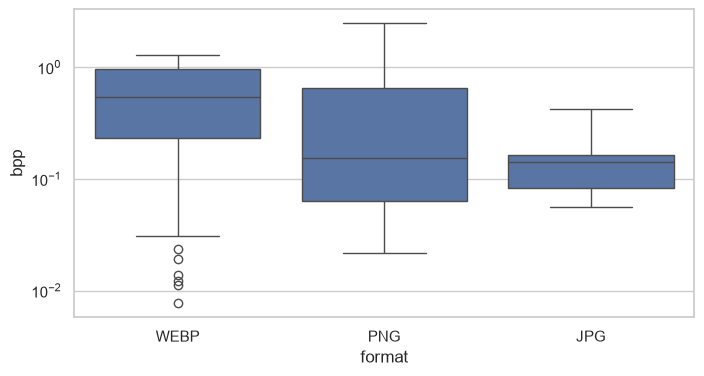

In [12]:
sns.boxplot(images, x="format", y="bpp", log_scale=True)

#### ⏹️ Orientation

<Axes: xlabel='orientation', ylabel='count'>

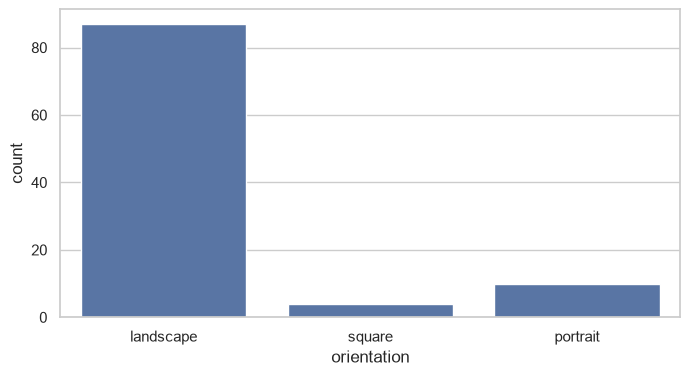

In [13]:
sns.countplot(images, x="orientation")

#### 🖥️ Resolution tier

<Axes: xlabel='tier', ylabel='count'>

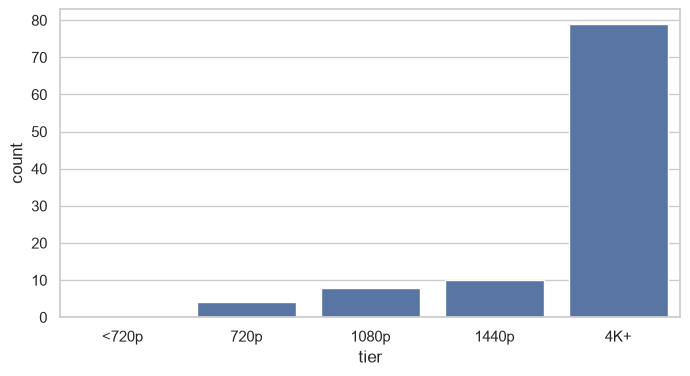

In [14]:
sns.countplot(images, x="tier", order=eda.TIERS)

#### 📐 Aspect ratio

<Axes: xlabel='count', ylabel='aspect'>

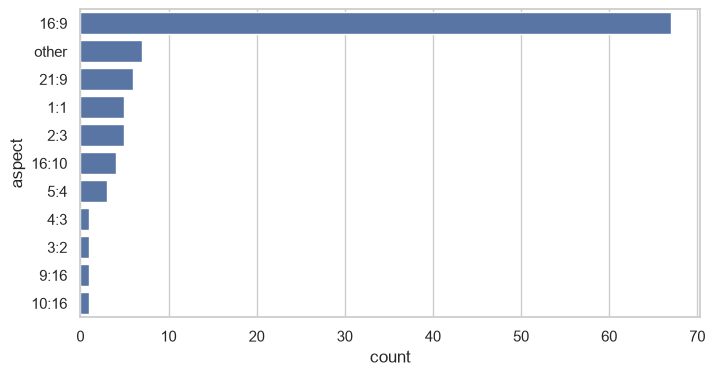

In [15]:
sns.countplot(images, y="aspect", order=images["aspect"].value_counts().index)

#### ⭐ Rating distribution

Rated images only.

<Axes: xlabel='rating', ylabel='count'>

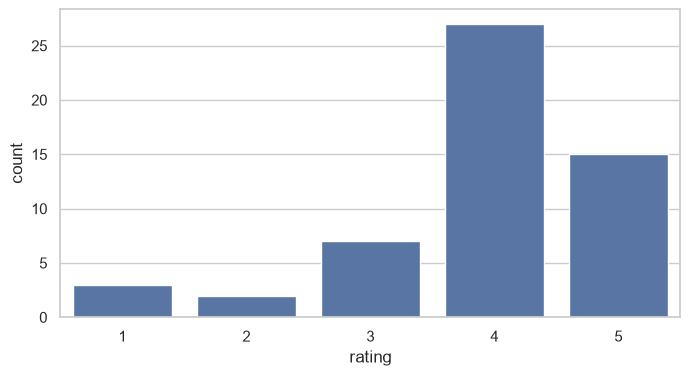

In [16]:
sns.countplot(images[images["rated"]], x="rating")

#### 🏷️ Top tags

<Axes: ylabel='tag_list'>

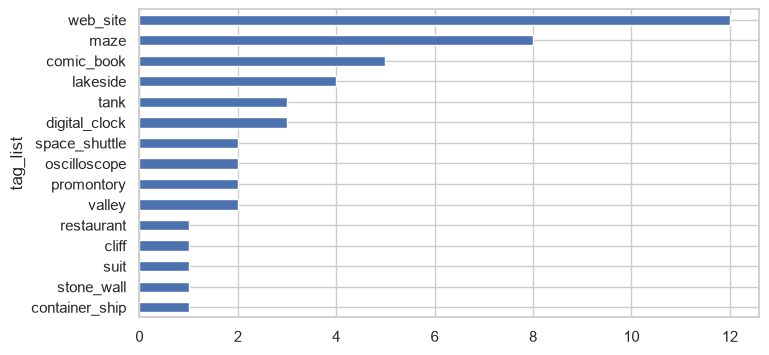

In [17]:
images["tag_list"].explode().value_counts().head(15)[::-1].plot.barh()

#### 📈 Collection growth

By file creation time (the import time is not stored).

Text(0, 0.5, 'images')

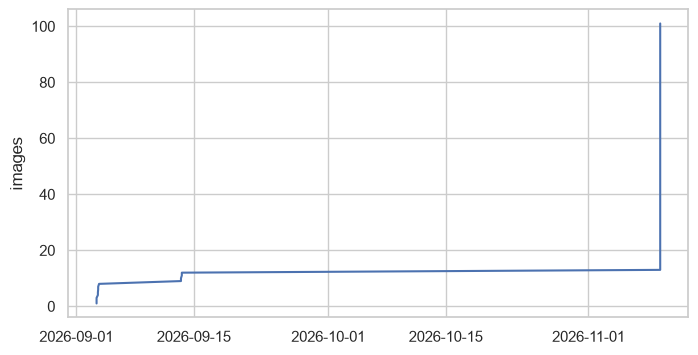

In [18]:
created = images["created_dt"].sort_values()
plt.plot(created, range(1, len(created) + 1))
plt.ylabel("images")

#### 🕑 When I collect images

Weekday x hour of the day (UTC).

<Axes: xlabel='hour', ylabel='weekday'>

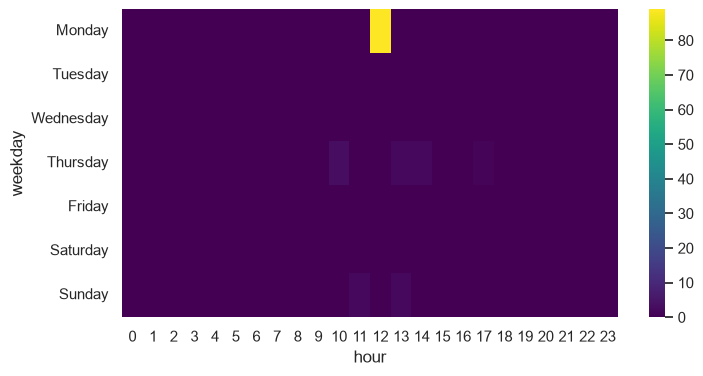

In [19]:
sns.heatmap(eda.hour_weekday(images), cmap="viridis")

#### Disk space taken

How much disk space the biggest files take.

<Axes: xlabel='% of files', ylabel='% of disk'>

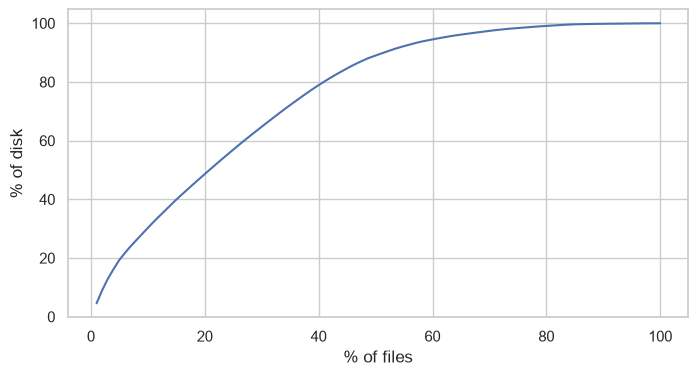

In [20]:
eda.pareto(images).plot(x="files_%", y="disk_%", legend=False, xlabel="% of files", ylabel="% of disk")

&nbsp;

### 🔗 **Relationships & Behavioral**

#### 🏷️ Tags co-occurrence

red = appear together more than by chance.

d:\Projects\FwLKhW\Eyeris\.venv\Lib\site-packages\seaborn\matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
d:\Projects\FwLKhW\Eyeris\.venv\Lib\site-packages\seaborn\matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


<Axes: xlabel='tag_list', ylabel='tag_list'>

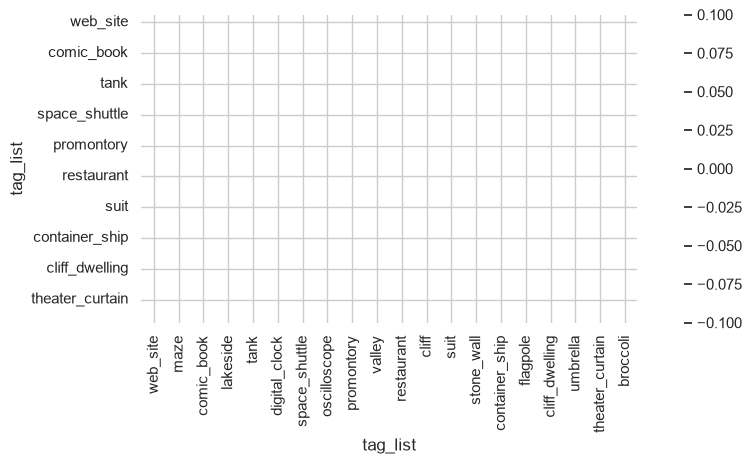

In [21]:
sns.heatmap(eda.tag_lift(images), cmap="coolwarm", center=0)

#### 🤯 Too big images

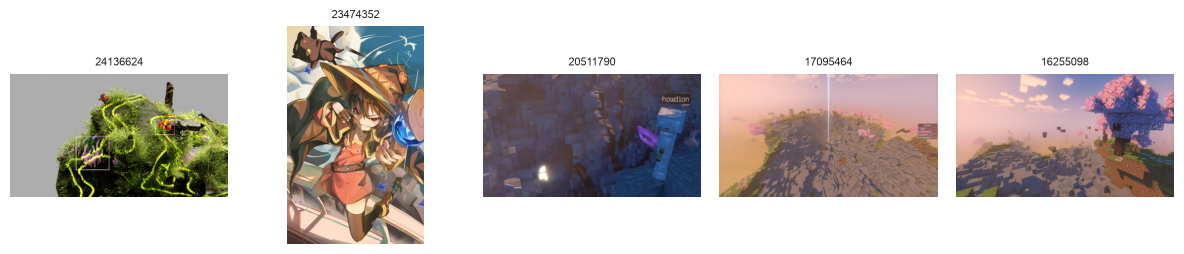

In [22]:
eda.contact_sheet(images.nlargest(5, "size"), caption="size")

#### 🤏 Too small images

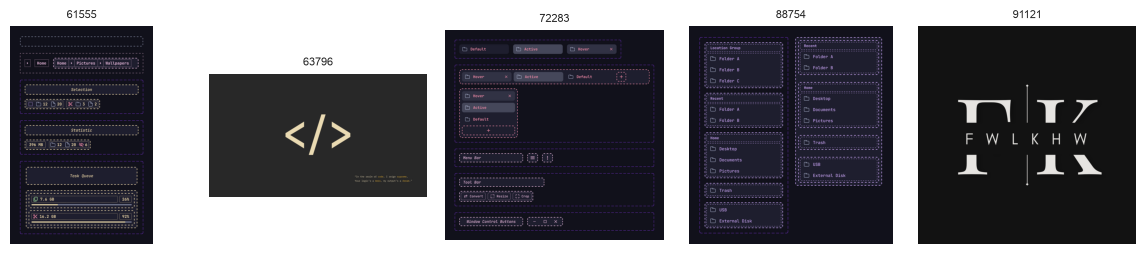

In [23]:
eda.contact_sheet(images.nsmallest(5, "size"), caption="size")

#### 🧓 Too old images

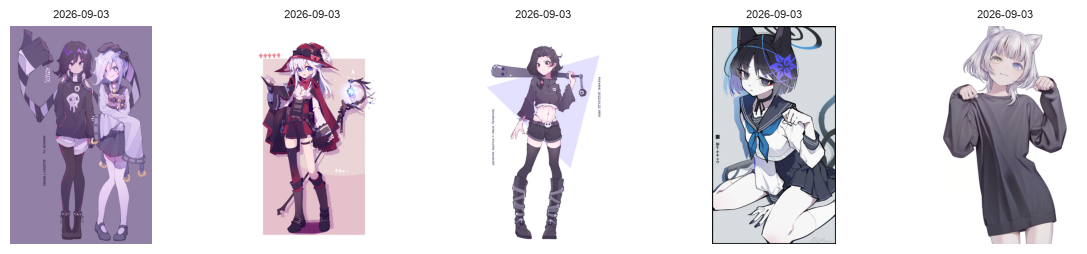

In [24]:
eda.contact_sheet(images.nsmallest(5, "created"), caption="created_dt")

#### 🎨 Color group distribution

Group of the most dominant color. Low chroma colors are black / gray / white.

<Axes: xlabel='color_group', ylabel='count'>

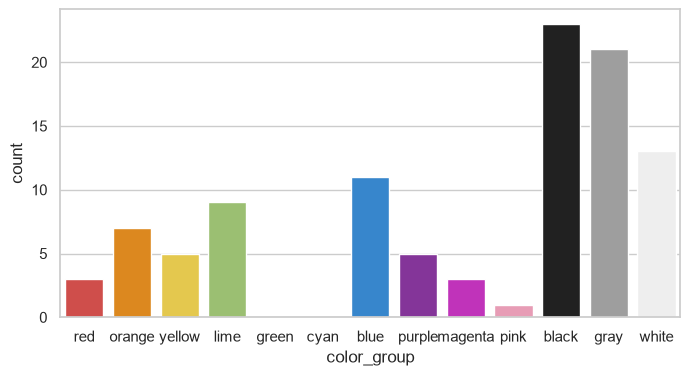

In [15]:
sns.countplot(images, x="color_group", hue="color_group", palette=eda.PALETTE, legend=False, dodge=False)

#### 🎨 Color group by lightness

<Axes: xlabel='color_group'>

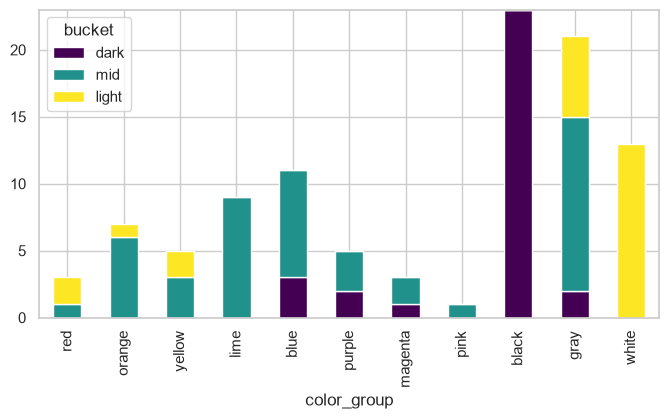

In [26]:
pd.crosstab(images["color_group"], images["bucket"]).plot.bar(stacked=True, colormap="viridis")

#### ⭐ Rating correlation

<Axes: >

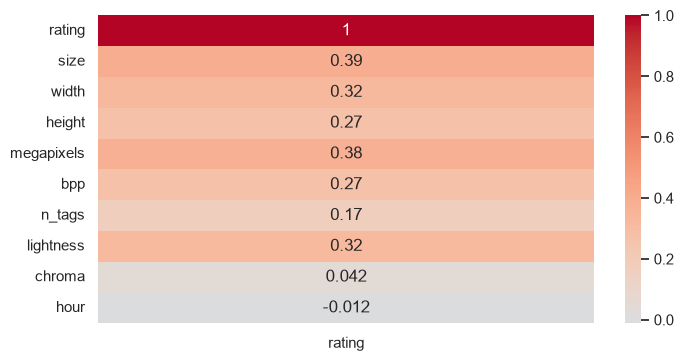

In [27]:
rated = images[images["rated"]]
sns.heatmap(rated[eda.NUMERIC].corr("spearman")[["rating"]], annot=True, cmap="coolwarm", center=0)

#### ⭐ Rating vs other properties

In [28]:
images[images["rated"]].groupby("rating")[["megapixels", "lightness", "chroma", "n_tags"]].mean()

,megapixels,lightness,chroma,n_tags
rating,,,,
1,3.871728,0.219958,0.027241,0.666667
2,6.071088,0.253604,0.030970,0.500000
3,8.838583,0.519332,0.030268,0.714286
4,10.980312,0.603539,0.057814,0.777778
5,12.692617,0.601373,0.042134,0.866667


&nbsp;

### 🧠 **Embeddings**

#### Load embeddings

In [29]:
emb, X = eda.load_embeddings(collection, images)
print(f"{len(emb)}/{len(images)} images have embeddings")

101/101 images have embeddings


#### Near-duplicates

Exact duplicates are already refused by hash, these are *visually* the same.

6 near-duplicate pairs


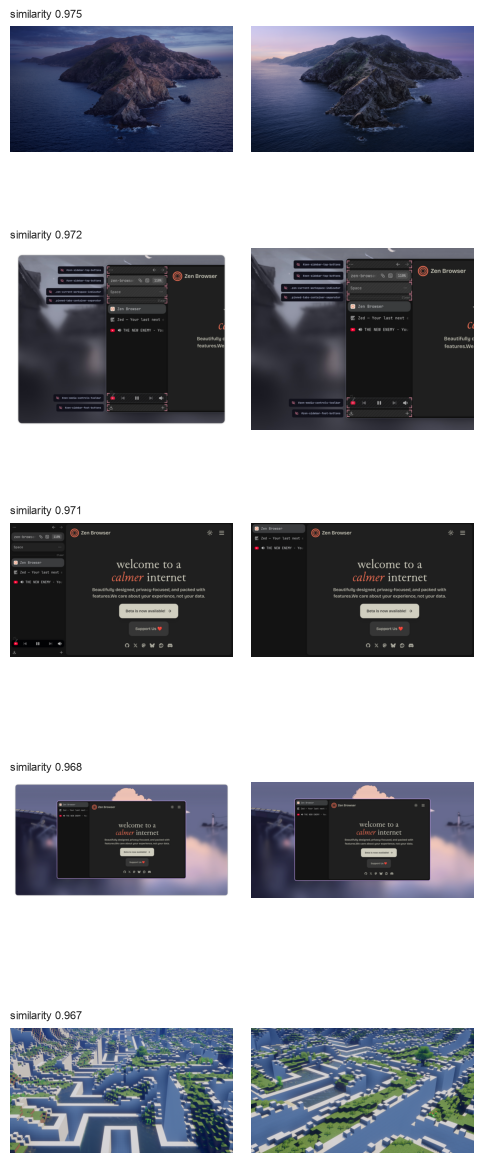

In [31]:
pairs = eda.near_duplicates(emb, X, thres=0.95)
print(f"{len(pairs)} near-duplicate pairs")
eda.show_pairs(pairs)

#### ✨ Taste profile

Predict rating from embedding, then show unrated images you may like.

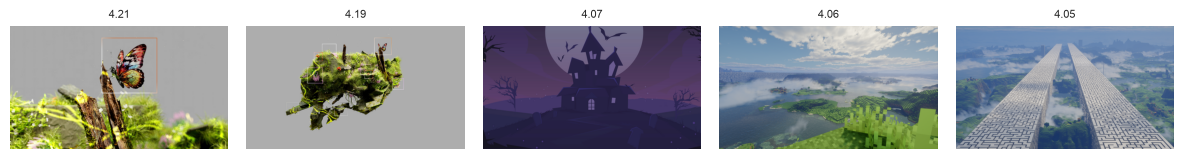

In [34]:
pred, score = eda.taste_profile(emb, X)
eda.contact_sheet(emb[~emb["rated"]].assign(pred=pred).nlargest(5, "pred"), caption="pred")

&nbsp;

### 🎉 **Fun part**

#### 🎨 The color of you

The color of you: gray (37% of all dominant colors)


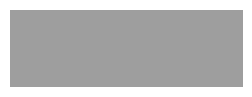

In [35]:
counts = eda.color_groups(images).stack().value_counts()
print(f"The color of you: {counts.index[0]} ({counts.iloc[0] / counts.sum():.0%} of all dominant colors)")
eda.swatch(counts.index[0])

#### ✨ Eyeris Wrapped

**Spotify Wrapped** mimic.

In [36]:
print(eda.wrapped(images))

✨ Eyeris Wrapped ✨
Images:          101
Color of you:    gray
Mood:            balanced (avg lightness 0.56)
Collector:       morning person 🐦
Busiest day:     Monday
Favorite format: WEBP
Top tag:         web_site


#### 🍹 Collection barcode

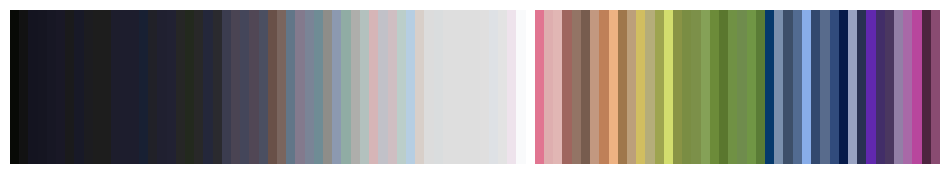

In [37]:
eda.barcode(images)